# Native pipeline output — drawn on the busStation BMP inputs

Parses `native_output.log` (the on-device native Sign-of-Life run) and, for each
frame, draws the reported **bounding boxes** and **centre of mass** on the
matching input image and prints the **SoL flag** with the object list.

Sources:

- Log: `native_output.log`
- Frames: `data_0_1fps_qvga_bmp/busStation/input/*.bmp` (QVGA 320×240)

Bbox convention (as reported by the pipeline): `[x y w h]` = top-left corner
`(x, y)` + size `(w, h)`, image origin top-left, `x` rightward, `y` downward.

In [1]:
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

LOG_PATH = Path("native_output.log")
INPUT_DIR = Path("data_0_1fps_qvga_bmp/busStation/input")

## 1. Parse the log

Each `--- Frame N/M: <name>.bmp ---` block carries one
`Sign-of-Life: flag=X objects=N` line and, for each detected region, a
`SoL box: [x y w h]. Area: A. Centroid: [cx cy]` line.

In [2]:
_HEADER = re.compile(r"--- Frame \d+/\d+: (\S+) ---")
_SOL_LINE = re.compile(r"Sign-of-Life: flag=(\d+) objects=(\d+)")
_SOL_BOX = re.compile(
    r"SoL box: \[(-?\d+) (-?\d+) (-?\d+) (-?\d+)\]\. "
    r"Area: (\d+)\. Centroid: \[(-?[\d.]+) (-?[\d.]+)\]"
)


def parse_log(path: Path) -> list[dict]:
    """Return per-frame records: {name, flag, objects:[{x,y,w,h,area,cx,cy}]}."""
    records: list[dict] = []
    current: dict | None = None
    for line in path.read_text().splitlines():
        m = _HEADER.search(line)
        if m:
            if current is not None:
                records.append(current)
            current = {"name": m.group(1), "flag": 0, "count": 0, "objects": []}
            continue
        if current is None:
            continue
        m = _SOL_LINE.search(line)
        if m:
            current["flag"] = int(m.group(1))
            current["count"] = int(m.group(2))
            continue
        m = _SOL_BOX.search(line)
        if m:
            x, y, w, h, area = (int(m.group(i)) for i in range(1, 6))
            cx, cy = float(m.group(6)), float(m.group(7))
            current["objects"].append(
                {"x": x, "y": y, "w": w, "h": h,
                 "area": area, "cx": cx, "cy": cy}
            )
    if current is not None:
        records.append(current)
    return records


records = parse_log(LOG_PATH)
print(f"parsed {len(records)} frames; {sum(r['flag'] for r in records)} Sign-of-Life")

parsed 6 frames; 3 Sign-of-Life


## 2. Table — SoL flag, bounding boxes and centres of mass

Per frame: flag, number of objects, and each object's `bbox = [x y w h]` and
`centroid = (cx, cy)`.

In [3]:
def format_object(obj: dict) -> str:
    return (f"bbox=[{obj['x']} {obj['y']} {obj['w']} {obj['h']}] "
            f"centroid=({obj['cx']:.2f}, {obj['cy']:.2f}) "
            f"area={obj['area']}")


rows = []
for record in records:
    objects = "; ".join(format_object(o) for o in record["objects"]) or "—"
    rows.append({
        "frame": record["name"],
        "SoL flag": record["flag"],
        "objects": record["count"],
        "detections (bbox / centroid / area)": objects,
    })

table = pd.DataFrame(rows)
print(table.to_string(index=False))
table

       frame  SoL flag  objects                                                                              detections (bbox / centroid / area)
in000001.bmp         0        0                                                                                                                —
in000241.bmp         0        0                                                                                                                —
in000481.bmp         1        1                                                            bbox=[46 70 49 94] centroid=(68.17, 113.32) area=2632
in000721.bmp         1        1                                                           bbox=[48 67 49 100] centroid=(71.62, 118.37) area=2399
in000961.bmp         1        2 bbox=[44 54 61 108] centroid=(76.79, 112.27) area=2592; bbox=[114 67 32 111] centroid=(128.97, 120.64) area=1915
in001201.bmp         0        0                                                                                                   

,frame,SoL flag,objects,detections (bbox / centroid / area)
0,in000001.bmp,0,0,—
1,in000241.bmp,0,0,—
2,in000481.bmp,1,1,"bbox=[46 70 49 94] centroid=(68.17, 113.32) ar..."
3,in000721.bmp,1,1,"bbox=[48 67 49 100] centroid=(71.62, 118.37) a..."
4,in000961.bmp,1,2,"bbox=[44 54 61 108] centroid=(76.79, 112.27) a..."
5,in001201.bmp,0,0,—


## 3. Overlays on the input images

Bounding boxes drawn in red (top-left + size), centre of mass as a yellow "×".
Each subplot titles the frame with its SoL flag; object annotations show area
and the centroid coordinates.

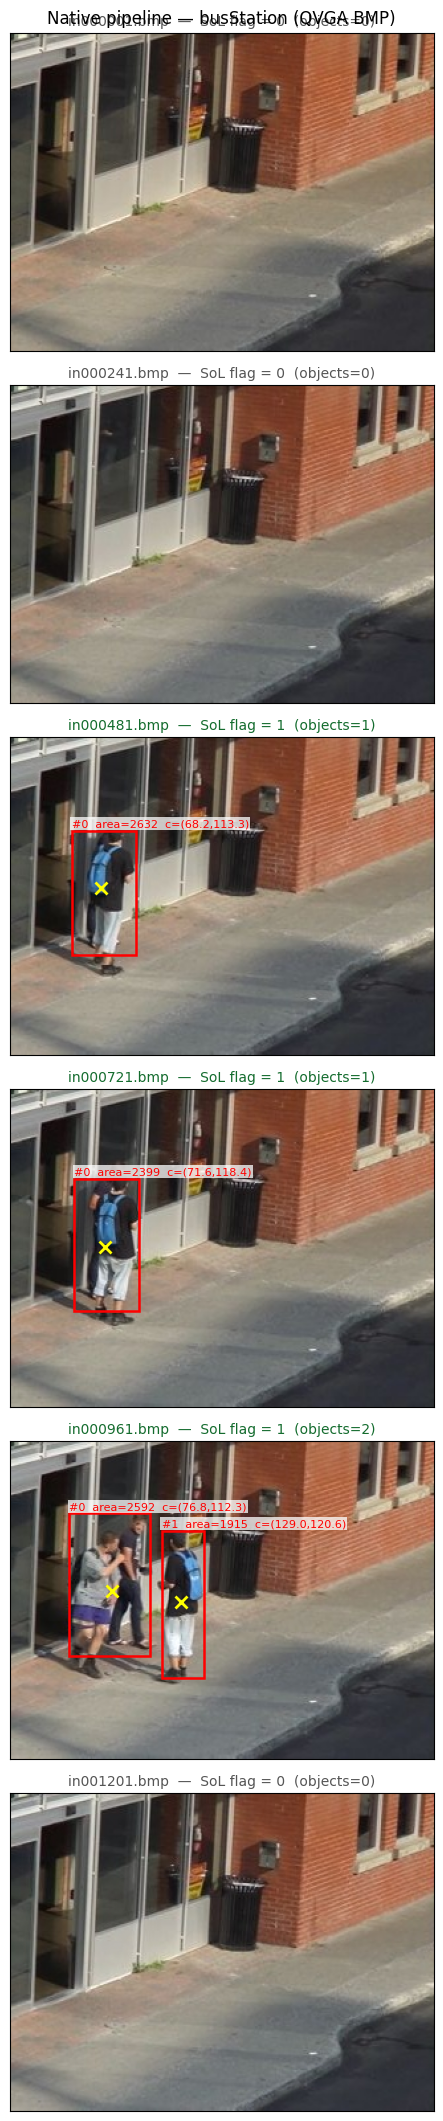

In [4]:
def draw_frame(ax, record: dict) -> None:
    """Load one BMP frame and overlay every SoL detection on it."""
    image = cv2.imread(str(INPUT_DIR / record["name"]))[:, :, ::-1]
    ax.imshow(image)
    ax.set_xticks([]); ax.set_yticks([])
    flag = record["flag"]
    title_colour = "#146c2e" if flag else "#555"
    ax.set_title(f"{record['name']}  —  SoL flag = {flag}  "
                 f"(objects={record['count']})",
                 fontsize=10, color=title_colour)
    for i, obj in enumerate(record["objects"]):
        ax.add_patch(Rectangle((obj["x"], obj["y"]), obj["w"], obj["h"],
                               fill=False, edgecolor="red", linewidth=1.8))
        ax.plot(obj["cx"], obj["cy"], marker="x", markersize=9,
                markeredgewidth=2, color="yellow")
        ax.text(obj["x"], obj["y"] - 3,
                f"#{i}  area={obj['area']}  c=({obj['cx']:.1f},{obj['cy']:.1f})",
                color="red", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.75))


fig, axes = plt.subplots(len(records), 1, figsize=(7.5, 3.6 * len(records)))
axes = np.atleast_1d(axes)
for ax, record in zip(axes, records):
    draw_frame(ax, record)
fig.suptitle("Native pipeline — busStation (QVGA BMP)", fontsize=12)
fig.tight_layout()
plt.show()